In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
from scipy import stats

In [2]:
DATA_PATH = '../../data'
MERGEGEN_RESULTS = '../../mergeGen/RESULTS'
SBCR_RESULTS = '../../sbcr'

MERGEGEN_DATASET2 = f"{MERGEGEN_RESULTS}/mergeGen_dataset2_JavaScript_model_dataset2_JavaScript_similarities.csv"
SBCR_DATASET2 = f"{SBCR_RESULTS}/rq2_JavaScript/RESULTS/results_evaluate_dataset2_JavaScript_combination_rq2_JavaScript_seed-3022024.xlsx"

DATASET2_COMPLETE = f"{DATA_PATH}/dataset2_JavaScript_complete.json" 
DATASET2_TESTING = f"{DATA_PATH}/dataset2_JavaScript_testing.json"
DATASET2_METADATA = f"{DATA_PATH}/dataset2_JavaScript_metadata.json"

## Dataset2

In [3]:
df_complete = pd.read_json(DATASET2_COMPLETE)

In [4]:
df_test = pd.read_json(DATASET2_TESTING)
df_test

,all_raw_base,all_raw_a,all_raw_b,all_raw_res,merge_id,chunk_number
0,"},{""../lang/isArray"":144,""./bindCallback"":98}]...","},{""../lang/isArray"":141,""./bindCallback"":95}]...","\n},{""../lang/isArray"":142,""./bindCallback"":96...","},{""../lang/isArray"":141,""./bindCallback"":95}]...",23593,76
1,"\t},\n\t\n\trefreshGrid : function(fromGridEle...","},\n\n refreshGrid: function(fromGridEl...","\n\t},\n\t\n\trefreshGrid : function(fromGridE...","},\n\n refreshGrid: function(fromGridEl...",77774,3
2,\t setShowChildren: function(visible){\n\t ...,\t verifyProps: function () {\n\t if...,\n\t setShowChildren: function(visible){\n\...,\t verifyProps: function () {\n\t if...,61241,13
3,"\t\t\tslotWidth = mathMin(axis.slotWidth, slot...","\t\t\tslotWidth = Math.min(axis.slotWidth, slo...","\n\t\t\tslotWidth = mathMin(axis.slotWidth, sl...","\t\t\tslotWidth = Math.min(axis.slotWidth, slo...",118829,16
4,"},{""./_descriptors"":30,""./_export"":34,""./_obje...","\n},{""./_descriptors"":31,""./_export"":35,""./_ob...","\n\n},{""./_descriptors"":31,""./_export"":35,""./_...","\n},{""./_descriptors"":31,""./_export"":35,""./_ob...",155033,245
...,...,...,...,...,...,...
5144,"$routeProvider.when('/images/:id/', {t...","$routeProvider.when('/images/:id*/', {...","\n $routeProvider.when('/images/:id/', ...","$routeProvider.when('/images/:id*/', {...",203419,1
5145,"<Image className=""theme-cover"" src...","<Image className=""theme-cover"" src...",\n,,34496,2
5146,if (process.env.NODE_ENV === 'production') {\n...,"function bailoutHooks(current, workInProgress,...",\nif (process.env.NODE_ENV === 'production') {...,"function bailoutHooks(current, workInProgress,...",43162,28
5147,WebhookEndpoint.getFresh({id: $rou...,\n $q.all([\n FormEndp...,\n // @uirouter-refactor this is ve...,\n $q.all([\n FormEndp...,122669,3


In [5]:
df_mergegen = pd.read_csv(MERGEGEN_DATASET2)
data = []
for index, row in df_mergegen.iterrows():
    chunk = df_complete.iloc[row['chunk_index']]
    chunk_id = f"{chunk['merge_id']}-{chunk['chunk_number']}"
    data.append(chunk_id)
df_mergegen['chunk_id'] = data
df_mergegen = df_mergegen.rename(columns={"complete_similarity": "sim_mergegen", "time": "time_mergegen", "similarity":"sim_mergegen_trunc", "parents_similarity":"mergegen_parents_sim"})
df_mergegen.sort_values('chunk_id')
df_mergegen

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim,result,chunk_id
0,27472,0.750000,0.666667,0.040468,1.000000,0.833333,0.916667,FAIL,196911-655
1,44031,0.997118,0.996904,0.342645,0.632911,0.948012,0.790462,FAIL,132648-2
2,35805,0.413514,0.416901,1.357956,0.416901,0.811475,0.614188,FAIL,55561-5
3,5646,0.763158,0.747664,0.307735,0.679012,0.654088,0.666550,FAIL,186409-1
4,17768,0.067797,0.037855,1.354022,0.096552,0.079395,0.087973,FAIL,132448-1
...,...,...,...,...,...,...,...,...,...
5144,1777,1.000000,1.000000,0.133554,1.000000,0.818182,0.909091,SUCCEED,179265-35
5145,41526,1.000000,1.000000,0.314328,1.000000,1.000000,1.000000,SUCCEED,89711-7
5146,24635,1.000000,1.000000,0.168448,1.000000,0.706897,0.853448,SUCCEED,187801-4
5147,37477,0.842553,1.000000,1.035379,0.665687,0.399317,0.532502,SUCCEED,161382-1


In [6]:
df_mergegen.describe()

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim
count,5149.000000,5149.000000,5149.000000,5149.000000,5149.000000,5149.000000,5149.000000
mean,25465.772577,0.867368,0.859217,0.520664,0.709729,0.670368,0.690048
std,14789.406424,0.238136,0.263065,0.459070,0.322154,0.335929,0.240918
min,4.000000,0.000000,0.000000,0.027127,0.000000,0.000000,0.000000
25%,12683.000000,0.787234,0.840532,0.174119,0.534428,0.447387,0.544152
50%,25379.000000,1.000000,1.000000,0.316305,0.834951,0.790698,0.709928
75%,38330.000000,1.000000,1.000000,0.728654,0.976109,0.962963,0.893258
max,51469.000000,1.000000,1.000000,1.530960,1.000000,1.000000,1.000000


In [7]:
df_sbcr = pd.read_excel(SBCR_DATASET2)
df_sbcr = df_sbcr.rename(columns={"solution_sim_lcs": "sim_sbcr", "time_seconds": "time_sbcr", "fitness": "fitness_sbcr"})
df_sbcr.sort_values('chunk_id')

,chunk_id,fitness_sbcr,sim_sbcr,status,time_sbcr
926,100159-1,0.902690,0.994778,ok,12.939296
1032,10096-1,0.926265,0.980803,ok,3.973917
1062,101479-1,0.643705,0.719136,ok,12.103017
995,101524-1,0.601941,0.292103,ok,65.247741
960,101528-1,0.916118,0.946363,ok,22.631450
...,...,...,...,...,...
1156,99230-1,0.993080,1.000000,ok,24.513543
416,9947-2,0.874936,0.735484,ok,7.194102
109,99477-1,0.901962,0.642943,ok,3.712581
477,99588-1,0.913930,1.000000,ok,19.721328


In [8]:
df_results = df_sbcr[['chunk_id', 'fitness_sbcr', 'sim_sbcr', 'time_sbcr']].merge(df_mergegen[['chunk_index', 'chunk_id', 'sim_mergegen', 'time_mergegen', 'mergegen_parents_sim']], on='chunk_id', suffixes=('_sbcr', '_mergegen'))
df_results

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim
0,4314-130,0.839161,1.000000,22.699592,8140,1.000000,0.168681,0.827331
1,161562-10,0.978183,0.959641,22.313421,26525,1.000000,0.262166,0.972083
2,156864-1,0.876318,0.747664,21.497840,44495,1.000000,0.186749,0.861000
3,37347-2,0.811602,1.000000,23.151990,42547,1.000000,0.201570,0.814852
4,194169-2,0.801728,0.648373,4.807784,30716,0.922025,1.348341,0.777483
...,...,...,...,...,...,...,...,...
1302,146509-2,0.910324,0.932765,21.175079,32859,0.978890,1.354858,0.963552
1303,68491-34,0.599088,0.991239,0.828199,10797,1.000000,0.616231,0.594733
1304,193794-4,0.855649,0.975684,1.564690,6000,1.000000,0.483217,0.826774
1305,90072-300,0.829473,0.848485,2.340068,42473,0.717949,0.370072,0.667072


In [9]:
print(df_results['sim_sbcr'].isnull().sum()) 
df_results_clean = df_results.dropna(subset=['sim_sbcr', 'sim_mergegen'])

12


In [10]:
print(df_results_clean[['sim_sbcr', 'sim_mergegen', 'time_sbcr', 'time_mergegen']].describe())

          sim_sbcr  sim_mergegen    time_sbcr  time_mergegen
count  1295.000000   1295.000000  1295.000000    1295.000000
mean      0.814622      0.877370    14.814825       0.531898
std       0.210181      0.223208    17.080710       0.449940
min       0.003898      0.000000     0.257957       0.040358
25%       0.706919      0.835708     3.069293       0.193806
50%       0.887179      1.000000    13.380127       0.334574
75%       0.994127      1.000000    22.536076       0.713305
max       1.000000      1.000000   231.273514       1.367894


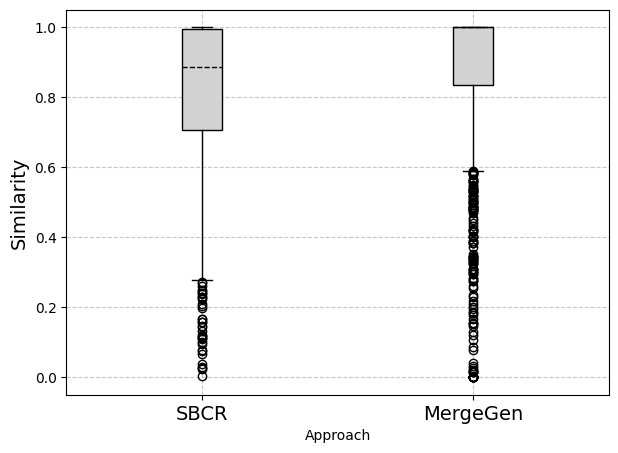

In [11]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_results_clean['sim_sbcr'], df_results_clean['sim_mergegen']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=True)

plt.xlabel('Approach')
plt.ylabel('Similarity', fontsize=14)
plt.xticks([1, 2], ['SBCR', 'MergeGen'], fontsize=14)
# plt.title('Similarity between random candidates and parents \n using each aggregation function', fontsize=16)
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('RQ2_JavaScript_similarity_boxplot.png', dpi=300) 
plt.show()  

In [17]:
stats.shapiro(df_results_clean['sim_mergegen'])

ShapiroResult(statistic=0.6214189529418945, pvalue=0.0)

In [18]:
for i in range(200, len(df_results_clean['sim_mergegen']), 50):
    stat, p_value = stats.shapiro(df_results_clean['sim_mergegen'][:i])
    print(stat, p_value)

0.6373720765113831 2.1104511665267488e-20
0.6568250060081482 3.585737331076583e-22
0.6505426168441772 2.3130080161458556e-24
0.6554365158081055 5.189705121675923e-26
0.6539163589477539 1.0804863729580937e-27
0.637001097202301 9.390775728154169e-30
0.6351503133773804 3.1911236830332003e-31
0.6355603933334351 1.6000119398678669e-32
0.6374998092651367 1.0968055651167935e-33
0.6330742835998535 5.271173234504529e-35
0.6303536891937256 3.330512202116626e-36
0.6274814009666443 2.3432537583292563e-37
0.6244390606880188 1.8091926252158778e-38
0.6251130104064941 2.117298921163904e-39
0.6248865723609924 2.517895119652761e-40
0.6185389757156372 1.8997403280851545e-41
0.6204966306686401 3.201966990982207e-42
0.6217705607414246 5.479076995510035e-43
0.6236170530319214 1.0509738482436128e-43
0.6302960515022278 3.363116314379561e-44
0.6242952346801758 4.203895392974451e-45
0.6222320795059204 0.0


In [13]:
# Normality test
stat_shapiro_sbcr, p_shapiro_sbcr = stats.shapiro(df_results_clean['sim_sbcr'])
stat_shapiro_mergegen, p_shapiro_mergegen = stats.shapiro(df_results_clean['sim_mergegen'])

print(f"Shapiro-Wilk Test for SBCR: W={stat_shapiro_sbcr}, p={p_shapiro_sbcr}")
print(f"Shapiro-Wilk Test for MergeGen: W={stat_shapiro_mergegen}, p={p_shapiro_mergegen}")

# Homocedasticity test
stat_levene, p_levene = stats.levene(df_results_clean['sim_sbcr'], df_results_clean['sim_mergegen'])

print(f"Levene Test: W={stat_levene}, p={p_levene}")

Shapiro-Wilk Test for SBCR: W=0.8331726789474487, p=9.539244563630849e-35
Shapiro-Wilk Test for MergeGen: W=0.6214189529418945, p=0.0
Levene Test: W=21.625556658336592, p=3.4805564749504185e-06


In [14]:
# Not normal and not homocedastic. We use non-parametric paired test Wilcoxon
pg.wilcoxon(df_results_clean['sim_sbcr'], df_results_clean['sim_mergegen'], alternative='two-sided')

# https://pingouin-stats.org/build/html/index.html
# Interpretation: https://peterstatistics.com/Terms/Correlations/RankBiserialCorrelation.html

,W-val,alternative,p-val,RBC,CLES
Wilcoxon,168883.0,two-sided,1.085536e-28,-0.394789,0.342809


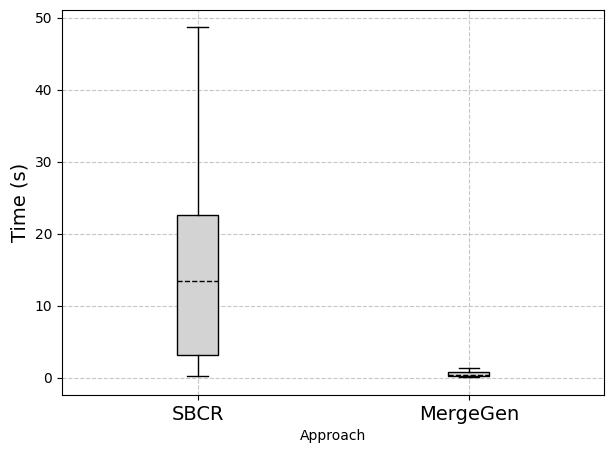

In [15]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_results_clean['time_sbcr'], df_results_clean['time_mergegen']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=False)

plt.xlabel('Approach')
plt.ylabel('Time (s)', fontsize=14)
plt.xticks([1, 2], ['SBCR', 'MergeGen'], fontsize=14)
# plt.title('Similarity between random candidates and parents \n using each aggregation function', fontsize=16)
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('RQ2_JavaScript_time_boxplot.png', dpi=300) 
plt.show()  